In [1]:
!pip install gym_bandits

In [2]:
import gym
import gym_bandits
import numpy as np


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [8]:
env = gym.make('MultiarmedBandits-v0')
print(env.observation_space)
print(env.action_space)

Discrete(1)
Discrete(10)


/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(


In [10]:
n_arms = env.action_space.n
num_episodes = 500

epsilon = 0.1

q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
reward_sums = np.zeros(n_arms)

all_rewards = []
action_history = []

for episode in range(num_episodes):
    env.reset()

    if np.random.rand() < epsilon:
        action = np.random.choice(n_arms)
    else:
        action = np.argmax(q_values)

    observation, reward, done, info = env.step(action)

    counts[action] += 1
    reward_sums[action] += reward

    q_values[action] = q_values[action] + (1.0 / counts[action]) * (reward - q_values[action])
    all_rewards.append(reward)
    action_history.append(action)

env.close()

/tmp/ipykernel_1129/1533569371.py:24: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  reward_sums[action] += reward


In [13]:
print("Estimated Q-values for each arm:")
print(q_values)

print("\nNumber of times each arm was selected:")
print(counts.astype(int))

print("\nAverage reward over all episodes:")
print(np.sum(all_rewards) / num_episodes)

Estimated Q-values for each arm:
[-0.30202501 -0.06829549 -1.54452887 -0.4815641  -0.09046711 -0.29113436
 -0.49655009 -0.3207812  -0.08795032 -0.00167929]

Number of times each arm was selected:
[  5  10   7   8 137  14   4   7 120 188]

Average reward over all episodes:
-0.09685716661695362


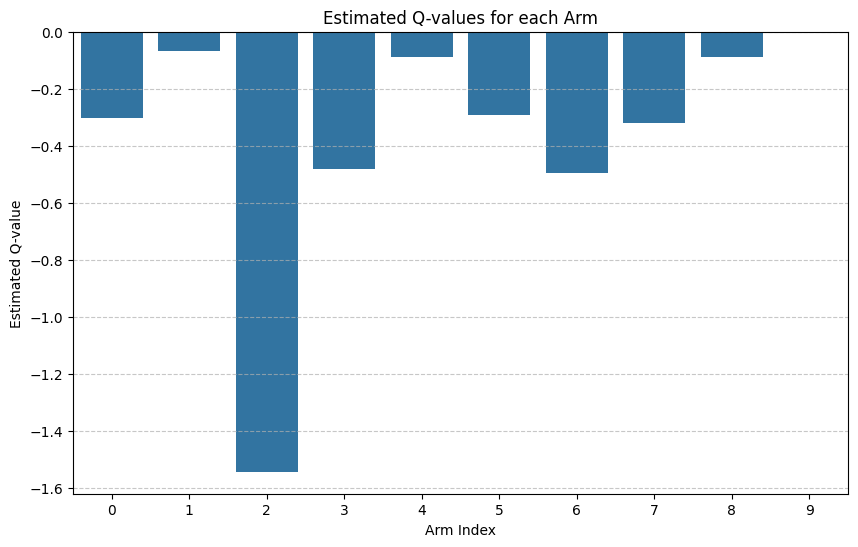

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting Estimated Q-values for each arm
plt.figure(figsize=(10, 6))
sns.barplot(x=np.arange(len(q_values)), y=q_values)
plt.xlabel('Arm Index')
plt.ylabel('Estimated Q-value')
plt.title('Estimated Q-values for each Arm')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

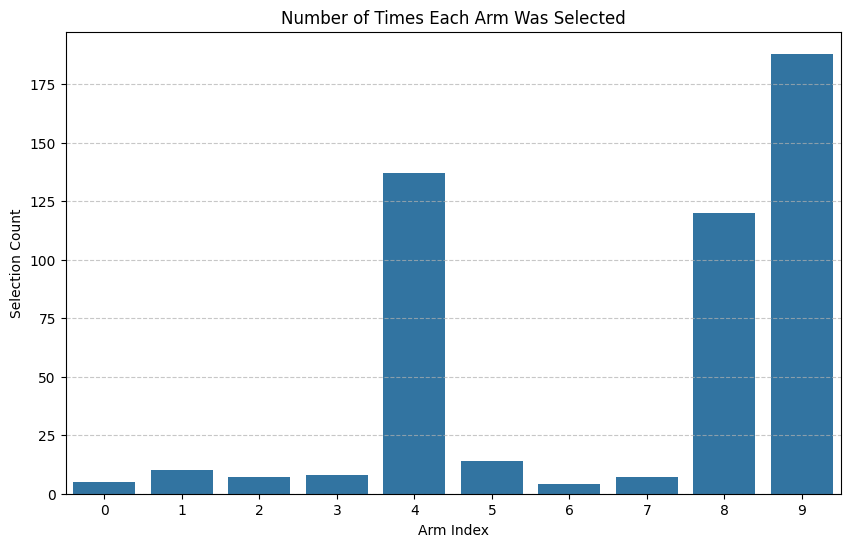

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [15]:
plt.figure(figsize=(10, 6))
sns.barplot(x=np.arange(len(counts)), y=counts)
plt.xlabel('Arm Index')
plt.ylabel('Selection Count')
plt.title('Number of Times Each Arm Was Selected')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

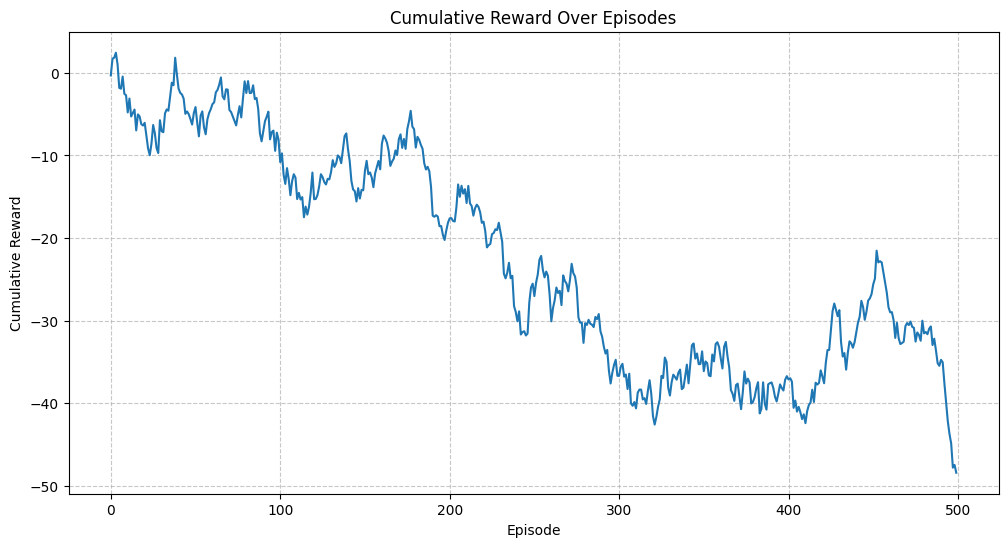

In [16]:
cumulative_rewards = np.cumsum(all_rewards)

plt.figure(figsize=(12, 6))
plt.plot(cumulative_rewards)
plt.xlabel('Episode')
plt.ylabel('Cumulative Reward')
plt.title('Cumulative Reward Over Episodes')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()